In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# RS-USFM project · Part 1 — Radiomics: extraction, stability, concepts (Path 1) and Expert A (Path 2)

**Project organisation (one notebook per part, all sharing `folds.csv` and `common.py` on Drive):**

| Part | Notebook | Produces |
|---|---|---|
| **1** | **Radiomics** (this notebook) | radiomic features, ICC stability, **concept targets for RS-USFM**, **Expert A** (mRMR + TabPFN) with metrics, SHAP, LIME |
| 2 | Deep expert (Expert B) | dual-stream ConvNeXt (lesion + ring) ensemble, metrics, Grad-CAM, LIME |
| 3 | RS-USFM (Expert C) | radiomics-supervised USFM, λ selection, consistency score, metrics, explanations |
| 4 | Fusion & comparison | Bayesian meta-learner, conformal BI-RADS 4 triage, all-expert comparison figures and tables |

**This notebook:**
1. Extracts PyRadiomics features from the **lesion** and a **peritumoral ring** (cached on Drive, resumable).
2. Tests feature **stability** under mask perturbation (ICC ≥ 0.75).
3. **Path 1:** builds the label-free **radiomic concepts** (family-wise PCA, fitted per training fold) → `concepts_fold{f}.csv`, the teacher targets for RS-USFM.
4. **Path 2 / Expert A:** mRMR feature selection (inside each training fold) + **TabPFN** with bootstrap uncertainty, compared with logistic regression and random forest.
5. Metrics (AUC, accuracy, balanced accuracy, sensitivity, specificity, precision, NPV, F1, AUPRC, Brier, with 95% CI), ROC / PR / calibration / confusion-matrix figures, **SHAP** and **LIME**.

Runtime: GPU (T4) recommended for TabPFN; extraction runs on CPU.

## 1. Setup

In [2]:
!pip -q install "git+https://github.com/AIM-Harvard/pyradiomics" SimpleITK tabpfn shap lime
# (PyRadiomics 3.1.0 from PyPI fails to build on recent Python; the GitHub version works.)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 8.8 MB/s eta 0:00:00


## 2. Paths and TabPFN access — edit this cell

**TabPFN one-time setup** (its weights are gated on Hugging Face):
1. Create a free account on huggingface.co, open https://huggingface.co/Prior-Labs/tabpfn_3_5 and accept the terms.
2. Create a *read* token (Settings → Access Tokens).
3. In Colab, click the 🔑 **Secrets** icon in the left bar, add a secret named `HF_TOKEN` with the token, and enable notebook access.

If this is not done, the notebook still runs: Expert A falls back to the best classical classifier and prints a clear warning.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys

BUSBRA_DIR = '/content/drive/MyDrive/BUSBRA'                      # <-- BUS-BRA folder
FOLDS_CSV  = '/content/drive/MyDrive/usfm_busbra_outputs/folds.csv' # <-- folds.csv from the USFM notebook
PROJ       = '/content/drive/MyDrive/rsusfm_project'                # all outputs of all parts go here
RAD_DIR, FIG_DIR, RES_DIR = f'{PROJ}/radiomics', f'{PROJ}/figures/part1', f'{PROJ}/results'
for d in (PROJ, RAD_DIR, FIG_DIR, RES_DIR): os.makedirs(d, exist_ok=True)

SEED = 42
N_ICC = 300          # lesions used for the stability (ICC) analysis
ICC_MIN = 0.75
K_MRMR = 30          # number of radiomic features selected for Expert A
N_BOOT_TABPFN = 5    # bootstrap members -> uncertainty of Expert A

try:
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
    print('HF_TOKEN loaded from Colab secrets')
except Exception as e:
    print('No HF_TOKEN secret found -> TabPFN may fall back to a classical model:', type(e).__name__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
No HF_TOKEN secret found -> TabPFN may fall back to a classical model: SecretNotFoundError


## 3. Shared utilities (`common.py`, saved on Drive and reused by every part)

In [4]:
%%writefile {PROJ}/common.py
"""
common.py — shared utilities for the RS-USFM project (BUS-BRA).
Used by every part (Expert A radiomics, Expert B deep, Expert C RS-USFM, fusion).

Contents
  * evaluation metrics with bootstrap 95% CIs
  * standard figures: ROC, PR, confusion matrix, calibration, metric comparison
  * a uniform results format so all experts can be compared later
"""
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

METRIC_ORDER = ["AUC", "Accuracy", "Balanced_Acc", "Sensitivity", "Specificity",
                "Precision", "NPV", "F1", "AUPRC", "Brier"]


# ----------------------------------------------------------------------------- metrics
def youden_threshold(y, p):
    """Threshold maximising sensitivity + specificity - 1 (fit on TRAINING predictions only)."""
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])


def point_metrics(y, p, thr=0.5):
    y, p = np.asarray(y).astype(int), np.asarray(p, float)
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {
        "AUC": roc_auc_score(y, p),
        "Accuracy": accuracy_score(y, yhat),
        "Balanced_Acc": balanced_accuracy_score(y, yhat),
        "Sensitivity": recall_score(y, yhat, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "Precision": precision_score(y, yhat, zero_division=0),
        "NPV": tn / (tn + fn) if (tn + fn) else np.nan,
        "F1": f1_score(y, yhat, zero_division=0),
        "AUPRC": average_precision_score(y, p),
        "Brier": brier_score_loss(y, p),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
    }


def bootstrap_ci(y, p, yhat_thr, groups=None, n_boot=1000, seed=42):
    """Patient-level (cluster) bootstrap 95% CI for every metric."""
    y, p, thr = np.asarray(y), np.asarray(p), np.asarray(yhat_thr)
    rng = np.random.default_rng(seed)
    if groups is None:
        groups = np.arange(len(y))
    groups = np.asarray(groups)
    ug = np.unique(groups)
    idx_by_g = {g: np.where(groups == g)[0] for g in ug}
    samples = {m: [] for m in METRIC_ORDER}
    for _ in range(n_boot):
        gs = rng.choice(ug, len(ug), replace=True)
        idx = np.concatenate([idx_by_g[g] for g in gs])
        if len(np.unique(y[idx])) < 2:
            continue
        yhat = (p[idx] >= thr[idx]).astype(int)
        tn, fp, fn, tp = confusion_matrix(y[idx], yhat, labels=[0, 1]).ravel()
        vals = {
            "AUC": roc_auc_score(y[idx], p[idx]), "Accuracy": accuracy_score(y[idx], yhat),
            "Balanced_Acc": balanced_accuracy_score(y[idx], yhat),
            "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
            "Specificity": tn / (tn + fp) if tn + fp else np.nan,
            "Precision": tp / (tp + fp) if tp + fp else np.nan,
            "NPV": tn / (tn + fn) if tn + fn else np.nan,
            "F1": f1_score(y[idx], yhat, zero_division=0),
            "AUPRC": average_precision_score(y[idx], p[idx]),
            "Brier": brier_score_loss(y[idx], p[idx]),
        }
        for k, v in vals.items():
            samples[k].append(v)
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for k, v in samples.items()}


def evaluate_oof(oof, name, out_dir, n_boot=1000):
    """
    oof: DataFrame with columns id, patient, fold, label, prob, thr
         (thr = decision threshold chosen on the TRAINING part of each fold).
    Returns a one-row summary (pooled metrics + 95% CI + per-fold mean±SD) and saves JSON.
    """
    y, p, thr = oof.label.values, oof.prob.values, oof.thr.values
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    pooled = point_metrics(y, p, 0.5)          # threshold-free metrics are correct here
    pooled.update({k: v for k, v in point_metrics(y, (p >= thr).astype(float), 0.5).items()
                   if k not in ("AUC", "AUPRC", "Brier")})
    ci = bootstrap_ci(y, p, thr, oof.patient.values, n_boot=n_boot)
    per_fold = []
    for f, g in oof.groupby("fold"):
        m = point_metrics(g.label, g.prob, 0.5)
        m.update({k: v for k, v in point_metrics(g.label, (g.prob >= g.thr).astype(float), 0.5).items()
                  if k not in ("AUC", "AUPRC", "Brier")})
        per_fold.append(m)
    per_fold = pd.DataFrame(per_fold)
    row = {"model": name}
    for m in METRIC_ORDER:
        row[m] = pooled[m]
        row[f"{m}_CI"] = f"{ci[m][0]:.3f}-{ci[m][1]:.3f}"
        row[f"{m}_fold_mean"] = per_fold[m].mean()
        row[f"{m}_fold_sd"] = per_fold[m].std()
    row.update({"TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn), "n": len(y)})
    os.makedirs(out_dir, exist_ok=True)
    with open(os.path.join(out_dir, f"metrics_{name}.json"), "w") as fh:
        json.dump(row, fh, indent=2, default=float)
    return row


def summary_table(rows, metrics=("AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "F1", "Brier")):
    """Paper-style table: 'value (95% CI)'."""
    t = pd.DataFrame(rows).set_index("model")
    return pd.DataFrame({m: [f"{t.loc[i, m]:.3f} ({t.loc[i, m + '_CI']})" for i in t.index]
                         for m in metrics}, index=t.index)


# ----------------------------------------------------------------------------- figures
def _save(fig, path):
    if path:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    plt.show()


def plot_roc(oofs, path=None, title="ROC curves (out-of-fold)"):
    """oofs: {model_name: oof DataFrame}"""
    fig, ax = plt.subplots(figsize=(5, 5))
    for name, o in oofs.items():
        fpr, tpr, _ = roc_curve(o.label, o.prob)
        ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(o.label, o.prob):.3f})")
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
    ax.set(xlabel="1 - Specificity", ylabel="Sensitivity", title=title, xlim=(0, 1), ylim=(0, 1.01))
    ax.legend(loc="lower right", fontsize=8)
    _save(fig, path)


def plot_pr(oofs, path=None, title="Precision-recall curves"):
    fig, ax = plt.subplots(figsize=(5, 5))
    for name, o in oofs.items():
        pr, rc, _ = precision_recall_curve(o.label, o.prob)
        ax.plot(rc, pr, lw=2, label=f"{name} (AP = {average_precision_score(o.label, o.prob):.3f})")
    ax.axhline(np.mean(next(iter(oofs.values())).label), ls="--", color="grey", lw=1)
    ax.set(xlabel="Recall (sensitivity)", ylabel="Precision", title=title, xlim=(0, 1), ylim=(0, 1.01))
    ax.legend(loc="lower left", fontsize=8)
    _save(fig, path)


def plot_confusion(oof, name, path=None):
    yhat = (oof.prob >= oof.thr).astype(int)
    cm = confusion_matrix(oof.label, yhat, labels=[0, 1])
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(3.8, 3.4))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.1%})", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.6 else "black", fontsize=10)
    ax.set_xticks([0, 1], ["Benign", "Malignant"]); ax.set_yticks([0, 1], ["Benign", "Malignant"])
    ax.set(xlabel="Predicted", ylabel="True", title=f"Confusion matrix: {name}")
    for s in ax.spines.values():
        s.set_visible(False)
    _save(fig, path)


def plot_calibration(oofs, path=None, n_bins=10):
    fig, ax = plt.subplots(figsize=(5, 5))
    for name, o in oofs.items():
        fp, mp = calibration_curve(o.label, o.prob, n_bins=n_bins, strategy="quantile")
        ax.plot(mp, fp, "o-", lw=1.5, ms=4, label=f"{name} (Brier = {brier_score_loss(o.label, o.prob):.3f})")
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
    ax.set(xlabel="Predicted probability", ylabel="Observed malignancy rate", title="Calibration",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left", fontsize=8)
    _save(fig, path)


def plot_metric_bars(rows, path=None,
                     metrics=("AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "F1")):
    t = pd.DataFrame(rows).set_index("model")
    n, k = len(t), len(metrics)
    w = 0.8 / n
    fig, ax = plt.subplots(figsize=(1.3 * k + 2, 4))
    for i, mdl in enumerate(t.index):
        vals = [t.loc[mdl, m] for m in metrics]
        lo = [vals[j] - float(t.loc[mdl, metrics[j] + "_CI"].split("-")[0]) for j in range(k)]
        hi = [float(t.loc[mdl, metrics[j] + "_CI"].split("-")[1]) - vals[j] for j in range(k)]
        ax.bar(np.arange(k) + i * w, vals, w, yerr=[lo, hi], capsize=2, label=mdl)
    ax.set_xticks(np.arange(k) + w * (n - 1) / 2, metrics)
    ax.set(ylim=(0, 1.05), ylabel="Score", title="Performance comparison (95% CI)")
    ax.legend(fontsize=8, ncol=min(n, 4), loc="lower center", bbox_to_anchor=(0.5, -0.32))
    _save(fig, path)


def save_oof(oof, name, out_dir):
    """Uniform OOF file: id, patient, fold, label, prob, logit_mean, logit_sd, thr."""
    cols = ["id", "patient", "fold", "label", "prob", "logit_mean", "logit_sd", "thr"]
    oof[cols].to_csv(os.path.join(out_dir, f"oof_{name}.csv"), index=False)


def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    return np.log(p / (1 - p))


Overwriting /content/drive/MyDrive/rsusfm_project/common.py


In [5]:
sys.path.insert(0, PROJ)
import importlib, common; importlib.reload(common)
from common import *
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore')

## 4. Master table: folds + BUS-BRA metadata (BI-RADS, scanner)

In [6]:
import glob
folds = pd.read_csv(FOLDS_CSV)
meta = pd.read_csv(glob.glob(f'{BUSBRA_DIR}/**/bus_data.csv', recursive=True)[0])
meta = meta.rename(columns={c: c.strip() for c in meta.columns})
id_col = [c for c in meta.columns if c.lower() == 'id'][0]
meta['id'] = meta[id_col].astype(str).str.replace('.png', '', regex=False)
keep = [c for c in meta.columns if c.lower() in ('birads', 'device', 'histology')]
master = folds.merge(meta[['id'] + keep], on='id', how='left')
master.columns = [c if c not in keep else c.lower() for c in master.columns]
master.to_csv(f'{PROJ}/master.csv', index=False)
print(master.shape); display(master.head(3))
for c in ('birads', 'device'):
    if c in master: display(pd.crosstab(master[c], master.label, margins=True))

(1875, 9)


,id,patient,label,fold,img_path,mask_path,histology,birads,device
0,bus_0001-l,1,1,0,/content/drive/MyDrive/BUSBRA/Images/bus_0001-...,/content/drive/MyDrive/BUSBRA/Masks/mask_0001-...,invasive ductal carcinoma,4,GE Logiq 7 @10-14MHz
1,bus_0001-r,1,1,0,/content/drive/MyDrive/BUSBRA/Images/bus_0001-...,/content/drive/MyDrive/BUSBRA/Masks/mask_0001-...,invasive ductal carcinoma,4,GE Logiq 7 @10-14MHz
2,bus_0002-l,2,0,4,/content/drive/MyDrive/BUSBRA/Images/bus_0002-...,/content/drive/MyDrive/BUSBRA/Masks/mask_0002-...,fibroadenoma,4,GE Logiq 7 @10-14MHz


label,0,1,All
birads,,,
2,552,10,562
3,432,31,463
4,280,413,693
5,4,153,157
All,1268,607,1875


label,0,1,All
device,,,
GE Logiq 5 @10-12MHz,566,243,809
GE Logiq 7 @10-14MHz,617,285,902
Toshiba Aplio 300 @12-14 MHz,71,68,139
U-Systems @10-14MHz,14,11,25
All,1268,607,1875


## 5. Radiomic feature extraction: lesion + peritumoral ring
- Ring width = 20% of the lesion's equivalent diameter (min 5 px). Proportional, because pixel spacing differs between scanners.
- Image types: Original + Wavelet (LoG is not available on single 2D slices in PyRadiomics).
- Intensities z-normalised per image (`normalize`), 32 grey-level bins — reduces scanner dependence.
- Shape features are computed for the lesion only (meaningless for a ring).
- Results are cached in chunks on Drive: if Colab disconnects, re-run the cell and it resumes.

In [7]:
import logging, SimpleITK as sitk
from PIL import Image
from scipy import ndimage as ndi
from joblib import Parallel, delayed
from radiomics import featureextractor
logging.getLogger('radiomics').setLevel(logging.ERROR)

SETTINGS = dict(force2D=True, force2Ddimension=0, binCount=32, normalize=True, normalizeScale=100,
                removeOutliers=3, minimumROIDimensions=1, label=1)
TEXTURE = ['firstorder', 'glcm', 'glrlm', 'glszm', 'gldm', 'ngtdm']

def make_extractor(with_shape):
    ex = featureextractor.RadiomicsFeatureExtractor(**SETTINGS)
    ex.disableAllImageTypes(); ex.disableAllFeatures()
    ex.enableImageTypeByName('Original'); ex.enableImageTypeByName('Wavelet')
    for c in TEXTURE + (['shape2D'] if with_shape else []): ex.enableFeatureClassByName(c)
    return ex

def load_pair(img_path, mask_path):
    img = np.array(Image.open(img_path).convert('L'), dtype=np.float32)
    msk = np.array(Image.open(mask_path).convert('L')) > 127
    if msk.shape != img.shape:   # safety: resize mask to image grid
        msk = np.array(Image.fromarray(msk.astype(np.uint8) * 255).resize(img.shape[::-1], Image.NEAREST)) > 127
    return img, msk

def ring_from(lesion, frac=0.20, min_px=5):
    diam = 2 * np.sqrt(lesion.sum() / np.pi)
    w = max(min_px, int(round(frac * diam)))
    dist = ndi.distance_transform_edt(~lesion)
    return (dist > 0) & (dist <= w)

def perturb(lesion, kind):
    if kind == 'orig': return lesion
    if kind == 'erode':  out = ndi.binary_erosion(lesion, iterations=2)
    if kind == 'dilate': out = ndi.binary_dilation(lesion, iterations=2)
    return out if out.sum() > 20 else lesion

def extract_one(row_id, img_path, mask_path, kind='orig'):
    try:
        img, les = load_pair(img_path, mask_path)
        les = perturb(les, kind); ring = ring_from(les)
        I = sitk.GetImageFromArray(img[None])
        out = {'id': row_id}
        for region, m, shape in (('lesion', les, True), ('ring', ring, False)):
            f = make_extractor(shape).execute(I, sitk.GetImageFromArray(m.astype(np.uint8)[None]))
            out.update({f'{region}__{k}': float(v) for k, v in f.items() if not k.startswith('diagnostics')})
        return out
    except Exception as e:
        print('failed', row_id, type(e).__name__, e); return {'id': row_id}

def extract_all(frame, kind, tag, chunk=200, n_jobs=-1):
    done, parts = set(), sorted(glob.glob(f'{RAD_DIR}/{tag}_part*.csv'))
    for p in parts: done |= set(pd.read_csv(p, usecols=['id']).id)
    todo = frame[~frame.id.isin(done)]
    print(f'{tag}: {len(done)} cached, {len(todo)} to extract')
    for s in range(0, len(todo), chunk):
        sub = todo.iloc[s:s + chunk]
        rows = Parallel(n_jobs=n_jobs)(delayed(extract_one)(r.id, r.img_path, r.mask_path, kind) for r in sub.itertuples())
        pd.DataFrame(rows).to_csv(f'{RAD_DIR}/{tag}_part{len(parts) + s // chunk:03d}.csv', index=False)
        print(f'  {min(s + chunk, len(todo))}/{len(todo)}')
    return pd.concat([pd.read_csv(p) for p in sorted(glob.glob(f'{RAD_DIR}/{tag}_part*.csv'))]).drop_duplicates('id')

import time; t0 = time.time()
rad = extract_all(master, 'orig', 'rad_orig')
rad = master[['id']].merge(rad, on='id', how='left')
print(f'features: {rad.shape[1] - 1} | missing rows: {rad.iloc[:, 1:].isna().all(1).sum()} | {(time.time()-t0)/60:.1f} min')

rad_orig: 1000 cached, 875 to extract
  200/875
  400/875
  600/875
  800/875
  875/875
features: 939 | missing rows: 0 | 6.8 min


## 6. Stability analysis (ICC) under mask perturbation
The same features are re-extracted on `N_ICC` lesions with the mask eroded and dilated by 2 px (and the ring recomputed). ICC(2,1), absolute agreement, across the three versions. **No labels are used**, so this step does not leak outcome information.

rad_erode: 0 cached, 300 to extract
  200/300
  300/300
rad_dilate: 0 cached, 300 to extract
  200/300
  300/300
825 / 939 features stable (ICC >= 0.75) on 300 lesions


stable  total
region family                   
lesion firstorder      79     90
       glcm            95    120
       gldm            56     70
       glrlm           61     80
       glszm           60     80
       ngtdm           20     25
       shape2D          9      9
ring   firstorder      85     90
       glcm           119    120
       gldm            67     70
       glrlm           73     80
       glszm           76     80
       ngtdm           25     25

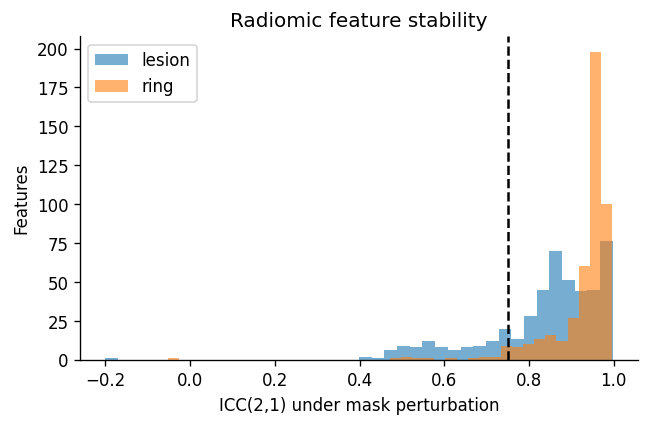

In [8]:
rng = np.random.default_rng(SEED)
icc_ids = rng.choice(master.id.values, size=min(N_ICC, len(master)), replace=False)
sub = master[master.id.isin(icc_ids)]
versions = {'orig': rad[rad.id.isin(icc_ids)]}
for kind in ('erode', 'dilate'):
    versions[kind] = extract_all(sub, kind, f'rad_{kind}')

def icc21(Y):                       # Y: (n_subjects, k_raters, n_features)
    n, k, _ = Y.shape
    g = Y.mean((0, 1)); rm = Y.mean(1); cm = Y.mean(0)
    msr = k * ((rm - g) ** 2).sum(0) / (n - 1)
    msc = n * ((cm - g) ** 2).sum(0) / (k - 1)
    sse = ((Y - rm[:, None, :] - cm[None, :, :] + g) ** 2).sum((0, 1))
    mse = sse / ((n - 1) * (k - 1))
    return (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)

feat_cols = [c for c in rad.columns if c != 'id']
ids_ok = set.intersection(*[set(v.dropna(subset=feat_cols, how='any').id) for v in versions.values()])
Y = np.stack([versions[k].set_index('id').loc[sorted(ids_ok), feat_cols].values for k in ('orig', 'erode', 'dilate')], 1)
icc = pd.Series(icc21(Y.astype(float)), index=feat_cols).fillna(0)
var_ok = rad[feat_cols].std() > 1e-8
stable = [c for c in feat_cols if icc[c] >= ICC_MIN and var_ok[c] and rad[c].notna().mean() > 0.99]
icc.rename('ICC').to_csv(f'{RAD_DIR}/icc.csv')
print(f'{len(stable)} / {len(feat_cols)} features stable (ICC >= {ICC_MIN}) on {len(ids_ok)} lesions')

def fclass(c):                       # 'lesion__wavelet-LH_glcm_Contrast' -> ('lesion', 'glcm')
    region, name = c.split('__'); return region, name.split('_')[1]
tab = pd.DataFrame([(*fclass(c), icc[c] >= ICC_MIN) for c in feat_cols], columns=['region', 'family', 'stable'])
display(tab.groupby(['region', 'family']).stable.agg(['sum', 'count']).rename(columns={'sum': 'stable', 'count': 'total'}))

fig, ax = plt.subplots(figsize=(6, 3.5))
for region in ('lesion', 'ring'):
    ax.hist(icc[[c for c in feat_cols if c.startswith(region)]].clip(-0.2, 1), bins=40, alpha=.6, label=region)
ax.axvline(ICC_MIN, ls='--', c='k'); ax.set(xlabel='ICC(2,1) under mask perturbation', ylabel='Features',
                                        title='Radiomic feature stability'); ax.legend()
fig.savefig(f'{FIG_DIR}/icc_histogram.png', bbox_inches='tight'); plt.show()

## 7. Path 1 — radiomic concepts: the teacher targets for RS-USFM
For each training fold: standardise the stable features, group them by **(region, feature family)**, and keep the first principal component of each group → one **concept** per group. Each concept is then standardised (mean 0, SD 1 on the training fold) and its sign aligned with the mean of the family's features, so that "high" keeps an interpretable meaning.

Saved: `concepts_fold{f}.csv` (all lesions, transformed with that fold's training fit) → used by Part 3.

concept groups: {'lesion_shape2D': 9, 'lesion_firstorder': 79, 'lesion_glcm': 95, 'lesion_glrlm': 61, 'lesion_glszm': 60, 'lesion_gldm': 56, 'lesion_ngtdm': 20, 'ring_firstorder': 85, 'ring_glcm': 119, 'ring_glrlm': 73, 'ring_glszm': 76, 'ring_gldm': 67, 'ring_ngtdm': 25}


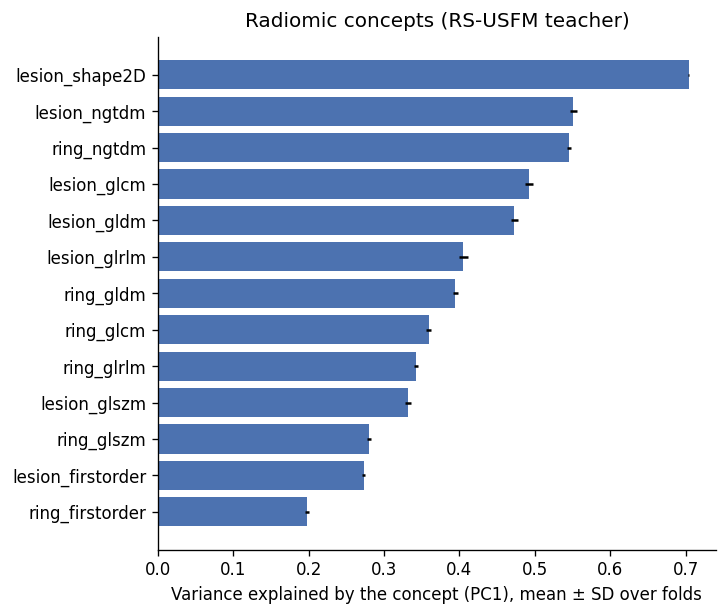

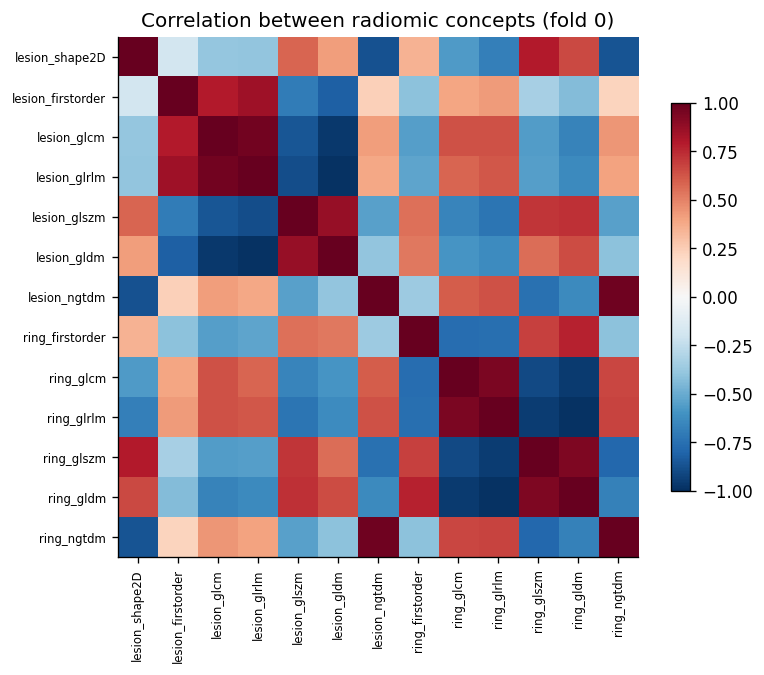

In [9]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

families = {}
for c in stable:
    families.setdefault('{}_{}'.format(*fclass(c)), []).append(c)
families = {k: v for k, v in families.items() if len(v) >= 2}
print('concept groups:', {k: len(v) for k, v in families.items()})

X_all = rad.set_index('id').loc[master.id, stable]
X_all = X_all.fillna(X_all.median())
ev_rows = []
for f in sorted(master.fold.unique()):
    tr = (master.fold != f).values
    concepts = pd.DataFrame({'id': master.id.values})
    for name, cols in families.items():
        sc = StandardScaler().fit(X_all.values[tr][:, [stable.index(c) for c in cols]])
        Ztr = sc.transform(X_all.loc[:, cols].values[tr]); Zall = sc.transform(X_all.loc[:, cols].values)
        pca = PCA(1, random_state=SEED).fit(Ztr)
        s_all = pca.transform(Zall)[:, 0]; s_tr = s_all[tr]
        sign = np.sign(np.corrcoef(s_tr, Ztr.mean(1))[0, 1]) or 1.0
        s_all = sign * (s_all - s_tr.mean()) / (s_tr.std() + 1e-8)
        concepts[name] = s_all
        ev_rows.append({'fold': f, 'concept': name, 'n_features': len(cols), 'explained_var': pca.explained_variance_ratio_[0]})
    concepts.to_csv(f'{RAD_DIR}/concepts_fold{f}.csv', index=False)
ev = pd.DataFrame(ev_rows); ev.to_csv(f'{RAD_DIR}/concepts_explained_variance.csv', index=False)
evm = ev.groupby('concept').explained_var.agg(['mean', 'std']).sort_values('mean')

fig, ax = plt.subplots(figsize=(6, 0.35 * len(evm) + 1))
ax.barh(evm.index, evm['mean'], xerr=evm['std'], color='#4C72B0')
ax.set(xlabel='Variance explained by the concept (PC1), mean ± SD over folds', title='Radiomic concepts (RS-USFM teacher)')
fig.savefig(f'{FIG_DIR}/concepts_explained_variance.png', bbox_inches='tight'); plt.show()

c0 = pd.read_csv(f'{RAD_DIR}/concepts_fold0.csv').drop(columns='id')
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(c0.corr(), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(c0.shape[1]), c0.columns, rotation=90, fontsize=7); ax.set_yticks(range(c0.shape[1]), c0.columns, fontsize=7)
plt.colorbar(im, ax=ax, shrink=.7); ax.set_title('Correlation between radiomic concepts (fold 0)')
fig.savefig(f'{FIG_DIR}/concepts_correlation.png', bbox_inches='tight'); plt.show()

## 8. Path 2 — Expert A: mRMR selection + TabPFN (with comparators)
Inside **each outer training fold only**:
1. standardise stable features;
2. **mRMR**: relevance = mutual information with the label, redundancy = mean |correlation| with already-selected features → `K_MRMR` features;
3. **TabPFN** fitted on `N_BOOT_TABPFN` patient-level bootstrap resamples → mean logit = prediction, SD of logits = **uncertainty** (used later by the Bayesian fusion);
4. comparators on the same features: L2 logistic regression and random forest;
5. the **decision threshold** is chosen by Youden's index on inner out-of-fold predictions of the training set (never on the test fold).

In [10]:
import torch
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
device = 'cuda' if torch.cuda.is_available() else 'cpu'

def mrmr(X, y, k, prefilter=300):
    rel = mutual_info_classif(X, y, random_state=SEED)
    cand = np.argsort(rel)[::-1][:prefilter]
    C = np.abs(np.corrcoef(X[:, cand], rowvar=False)); np.fill_diagonal(C, 0)
    sel = [0]
    while len(sel) < min(k, len(cand)):
        score = rel[cand] - C[:, sel].mean(1); score[sel] = -np.inf
        sel.append(int(np.argmax(score)))
    return cand[sel]

TABPFN_OK = None
def make_tabpfn():
    global TABPFN_OK
    if TABPFN_OK is False: return None
    from tabpfn import TabPFNClassifier
    if TABPFN_OK: return TabPFNClassifier(device=device, random_state=SEED)
    try:
        m = TabPFNClassifier(device=device, random_state=SEED)
        m.fit(np.random.randn(20, 3), np.r_[np.zeros(10), np.ones(10)])   # triggers the weight download
        TABPFN_OK = True; return TabPFNClassifier(device=device, random_state=SEED)
    except Exception as e:
        TABPFN_OK = False
        print('⚠️ TabPFN unavailable (', type(e).__name__, ') -> Expert A uses the best classical model. '
              'See section 2 to enable TabPFN.'); return None

MODELS = {
    'LogReg': lambda: LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000),
    'RandomForest': lambda: RandomForestClassifier(500, min_samples_leaf=3, class_weight='balanced_subsample',
                                                   n_jobs=-1, random_state=SEED),
}
if make_tabpfn() is not None: MODELS['TabPFN'] = make_tabpfn

def fit_predict(make, Xtr, ytr, Xte, gtr=None, n_boot=1):
    if n_boot == 1:
        m = make().fit(Xtr, ytr); p = m.predict_proba(Xte)[:, 1]
        return p, logit(p), np.full(len(p), np.nan)
    rng = np.random.default_rng(SEED); ug = np.unique(gtr); L = []
    for _ in range(n_boot):          # patient-level bootstrap
        idx = np.concatenate([np.where(gtr == g)[0] for g in rng.choice(ug, len(ug))])
        L.append(logit(make().fit(Xtr[idx], ytr[idx]).predict_proba(Xte)[:, 1]))
    L = np.stack(L); mu = L.mean(0)
    return 1 / (1 + np.exp(-mu)), mu, L.std(0)

y_all, g_all = master.label.values, master.patient.astype(str).values
oofs = {n: master[['id', 'patient', 'fold', 'label']].copy() for n in MODELS}
for o in oofs.values(): o[['prob', 'logit_mean', 'logit_sd', 'thr']] = np.nan
selected = {}
for f in sorted(master.fold.unique()):
    tr, te = (master.fold != f).values, (master.fold == f).values
    sc = StandardScaler().fit(X_all.values[tr]); Xtr, Xte = sc.transform(X_all.values[tr]), sc.transform(X_all.values[te])
    sel = mrmr(Xtr, y_all[tr], K_MRMR); selected[f] = [stable[i] for i in sel]
    Xtr_s, Xte_s = Xtr[:, sel], Xte[:, sel]
    inner = list(StratifiedGroupKFold(3, shuffle=True, random_state=SEED).split(Xtr_s, y_all[tr], g_all[tr]))
    for name, make in MODELS.items():
        p_in = np.zeros(tr.sum())                 # inner OOF -> threshold (training data only)
        for itr, ite in inner:
            p_in[ite] = fit_predict(make, Xtr_s[itr], y_all[tr][itr], Xtr_s[ite])[0]
        thr = youden_threshold(y_all[tr], p_in)
        nb = N_BOOT_TABPFN if name == 'TabPFN' else 1
        p, mu, sd = fit_predict(make, Xtr_s, y_all[tr], Xte_s, g_all[tr], n_boot=nb)
        oofs[name].loc[te, ['prob', 'logit_mean', 'logit_sd', 'thr']] = np.c_[p, mu, sd, np.full(te.sum(), thr)]
        print(f'fold {f} | {name:12s} AUC = {roc_auc_score(y_all[te], p):.3f} | thr = {thr:.2f}')

EXPERT_A = 'TabPFN' if 'TabPFN' in MODELS else max(MODELS, key=lambda n: roc_auc_score(oofs[n].label, oofs[n].prob))
for n, o in oofs.items(): save_oof(o, f'radiomics_{n}', RES_DIR)
save_oof(oofs[EXPERT_A], 'expertA', RES_DIR)
print('Expert A =', EXPERT_A, '-> saved oof_expertA.csv')

⚠️ TabPFN unavailable ( TabPFNLicenseError ) -> Expert A uses the best classical model. See section 2 to enable TabPFN.
fold 0 | LogReg       AUC = 0.920 | thr = 0.45
fold 0 | RandomForest AUC = 0.923 | thr = 0.37
fold 1 | LogReg       AUC = 0.910 | thr = 0.44
fold 1 | RandomForest AUC = 0.901 | thr = 0.37
fold 2 | LogReg       AUC = 0.930 | thr = 0.49
fold 2 | RandomForest AUC = 0.913 | thr = 0.39
fold 3 | LogReg       AUC = 0.906 | thr = 0.48
fold 3 | RandomForest AUC = 0.908 | thr = 0.43
fold 4 | LogReg       AUC = 0.950 | thr = 0.43
fold 4 | RandomForest AUC = 0.933 | thr = 0.37
Expert A = LogReg -> saved oof_expertA.csv


## 9. Results: metrics with 95% CI and figures

,AUC,Accuracy,Sensitivity,Specificity,Precision,F1,Brier
model,,,,,,,
Radiomics-LogReg,0.923 (0.905-0.940),0.863 (0.844-0.881),0.852 (0.816-0.886),0.868 (0.844-0.889),0.756 (0.713-0.794),0.801 (0.770-0.829),0.102 (0.091-0.114)
Radiomics-RandomForest,0.915 (0.896-0.934),0.846 (0.825-0.866),0.806 (0.763-0.841),0.865 (0.840-0.888),0.741 (0.697-0.785),0.772 (0.738-0.803),0.112 (0.103-0.122)


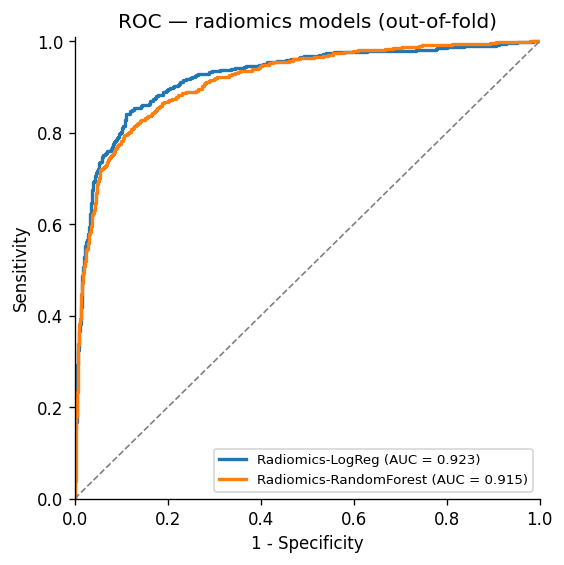

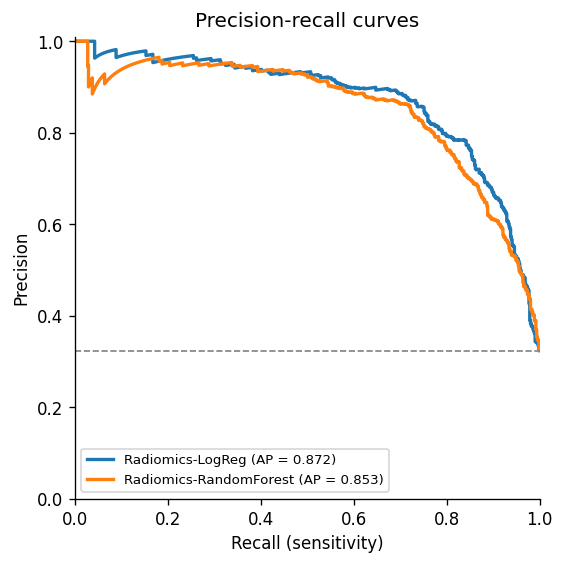

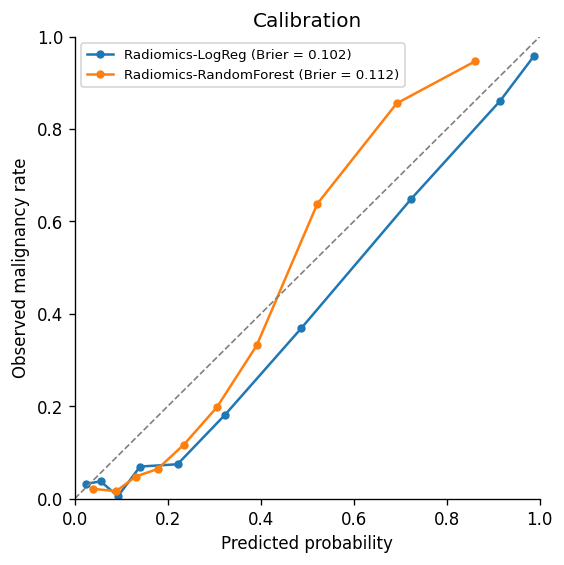

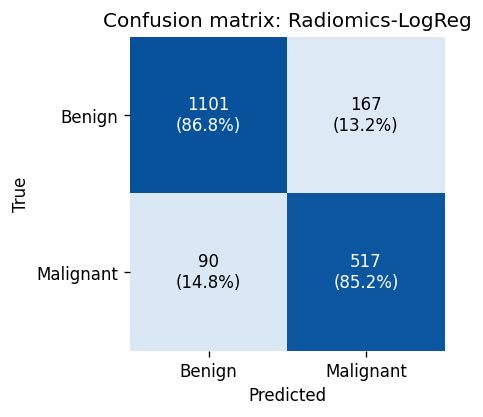

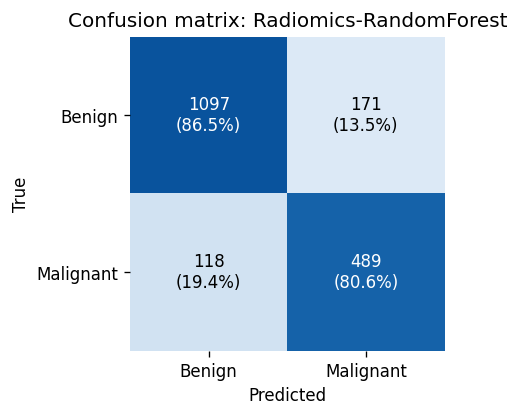

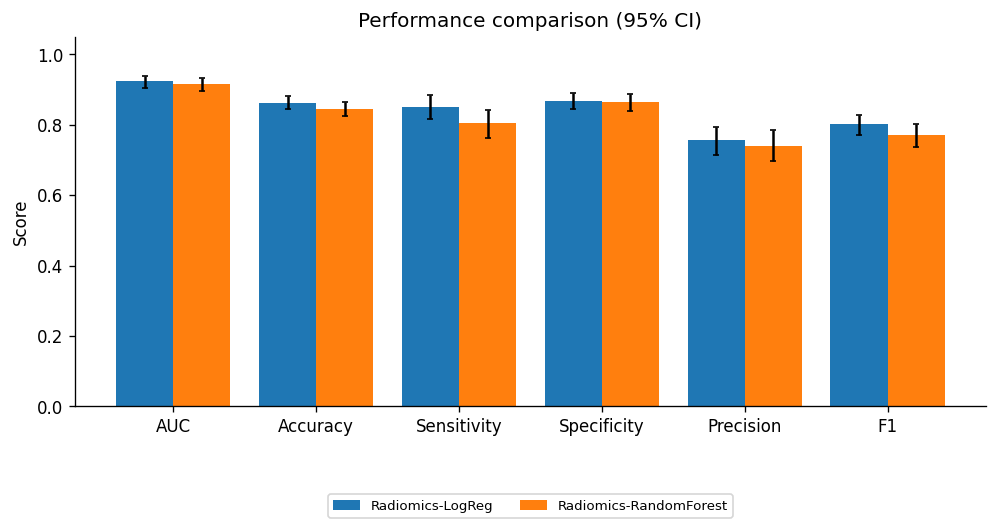

In [11]:
rows = [evaluate_oof(o, f'Radiomics-{n}', RES_DIR) for n, o in oofs.items()]
display(summary_table(rows))
pd.DataFrame(rows).to_csv(f'{RES_DIR}/part1_metrics_full.csv', index=False)

named = {f'Radiomics-{n}': o for n, o in oofs.items()}
plot_roc(named, f'{FIG_DIR}/roc_expertA.png', 'ROC — radiomics models (out-of-fold)')
plot_pr(named, f'{FIG_DIR}/pr_expertA.png')
plot_calibration(named, f'{FIG_DIR}/calibration_expertA.png')
for n, o in named.items(): plot_confusion(o, n, f'{FIG_DIR}/cm_{n}.png')
plot_metric_bars(rows, f'{FIG_DIR}/metrics_bars_expertA.png')

## 10. Feature-selection stability across folds

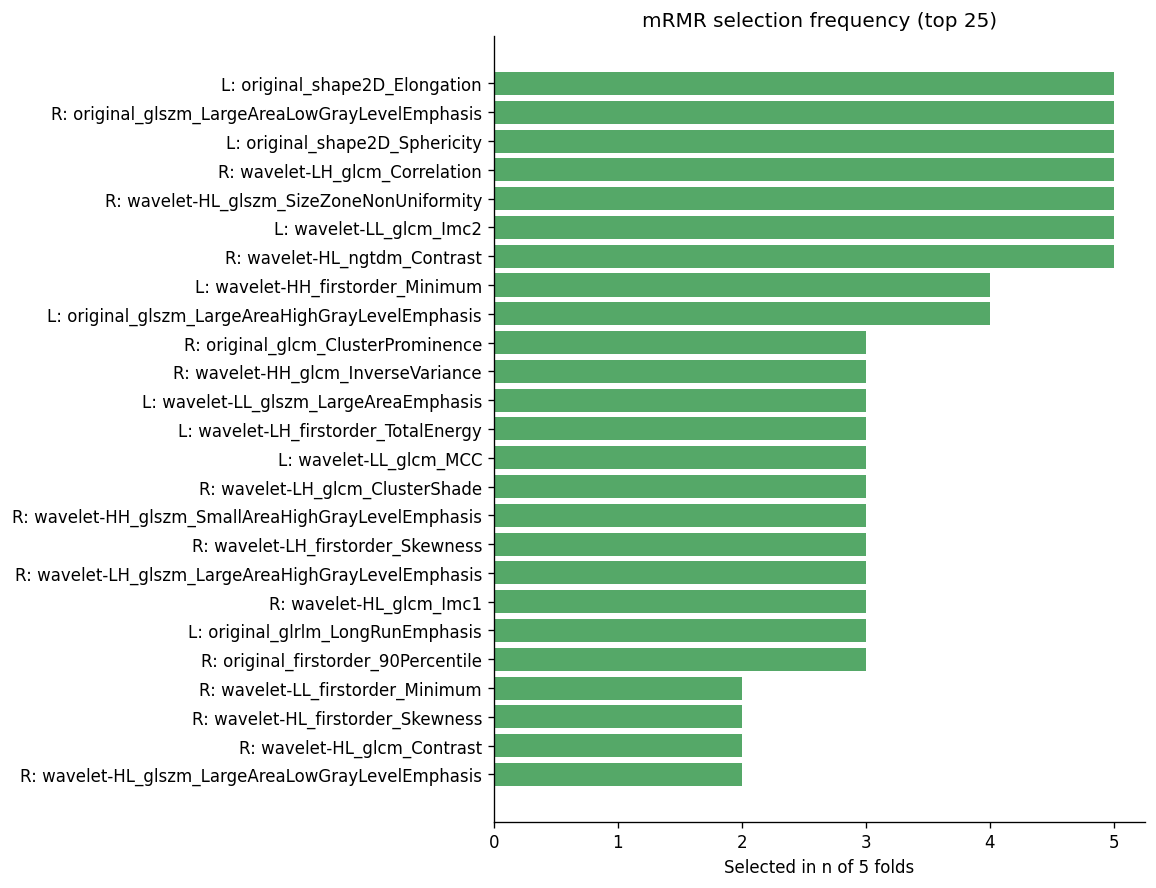

In [12]:
cnt = pd.Series([c for v in selected.values() for c in v]).value_counts()
top = cnt.head(25)[::-1]
fig, ax = plt.subplots(figsize=(7, 0.3 * len(top) + 1))
ax.barh([t.replace('lesion__', 'L: ').replace('ring__', 'R: ') for t in top.index], top.values, color='#55A868')
ax.set(xlabel=f'Selected in n of {len(selected)} folds', title='mRMR selection frequency (top 25)')
fig.savefig(f'{FIG_DIR}/mrmr_selection_frequency.png', bbox_inches='tight'); plt.show()
pd.DataFrame({f'fold{f}': pd.Series(v) for f, v in selected.items()}).to_csv(f'{RES_DIR}/expertA_selected_features.csv', index=False)

## 11. Explainability — SHAP (Expert A)
SHAP values for the Expert A model of fold 0, explaining its **test-fold** lesions (permutation explainer, model-agnostic, works for TabPFN). For a fast exact reference, SHAP is also shown for logistic regression.

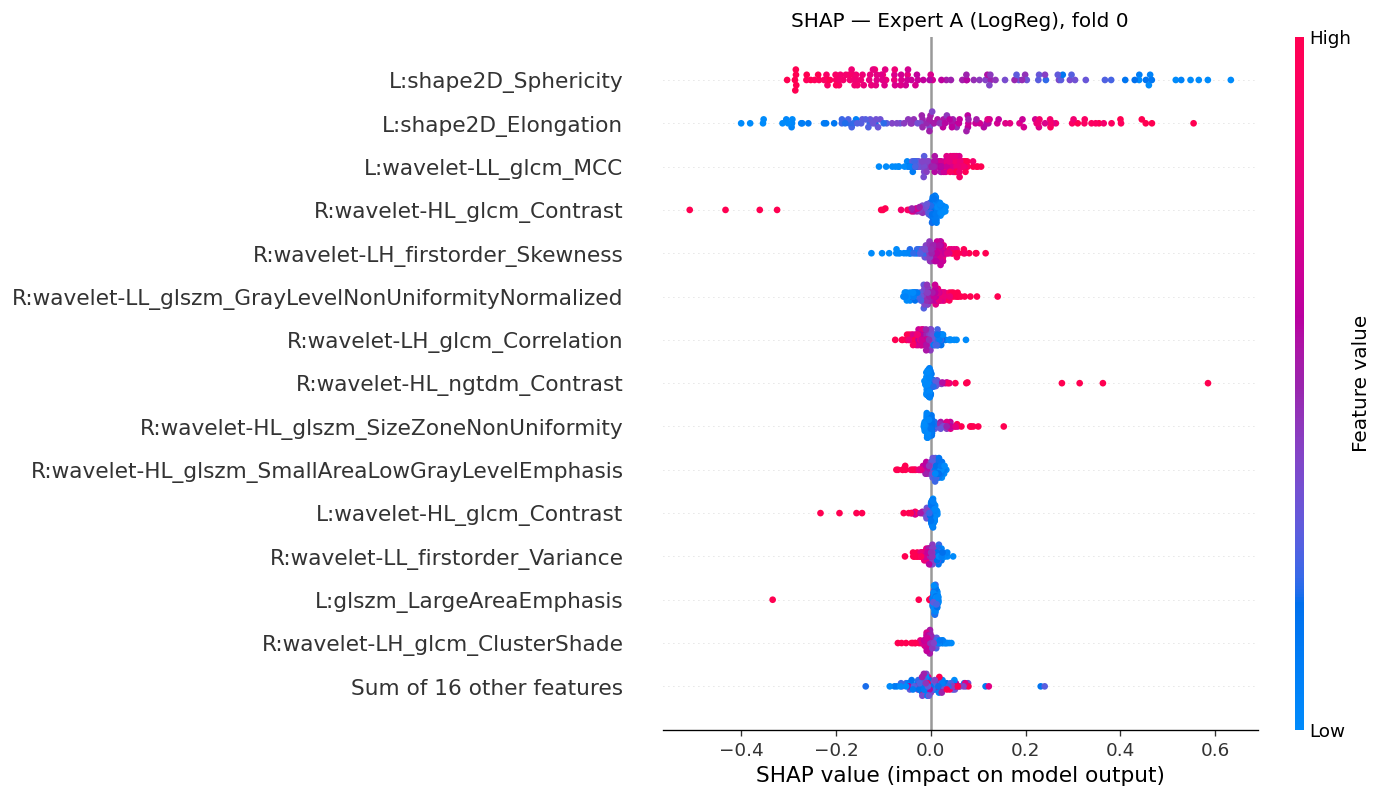

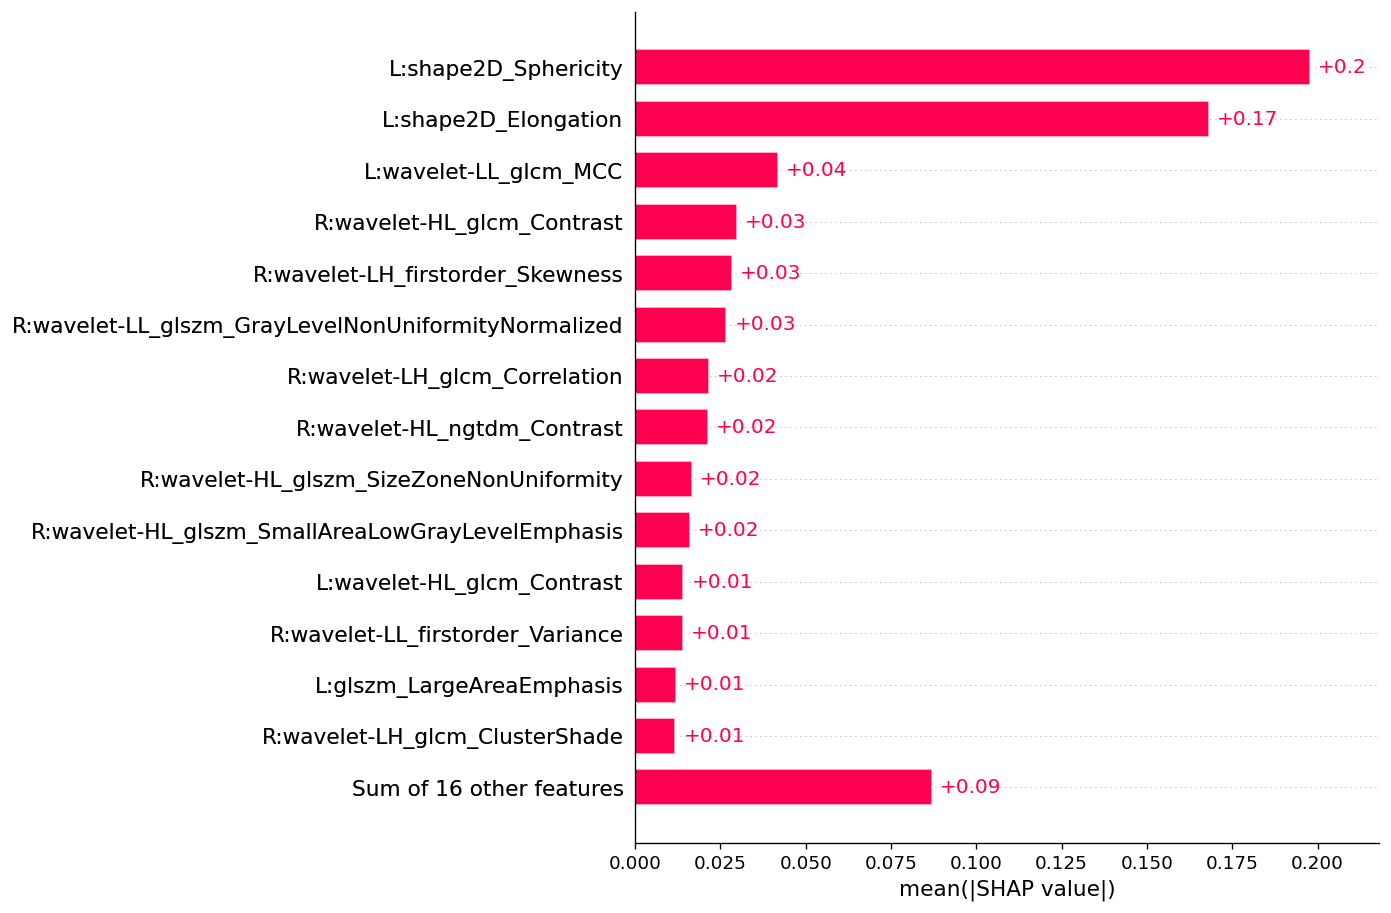

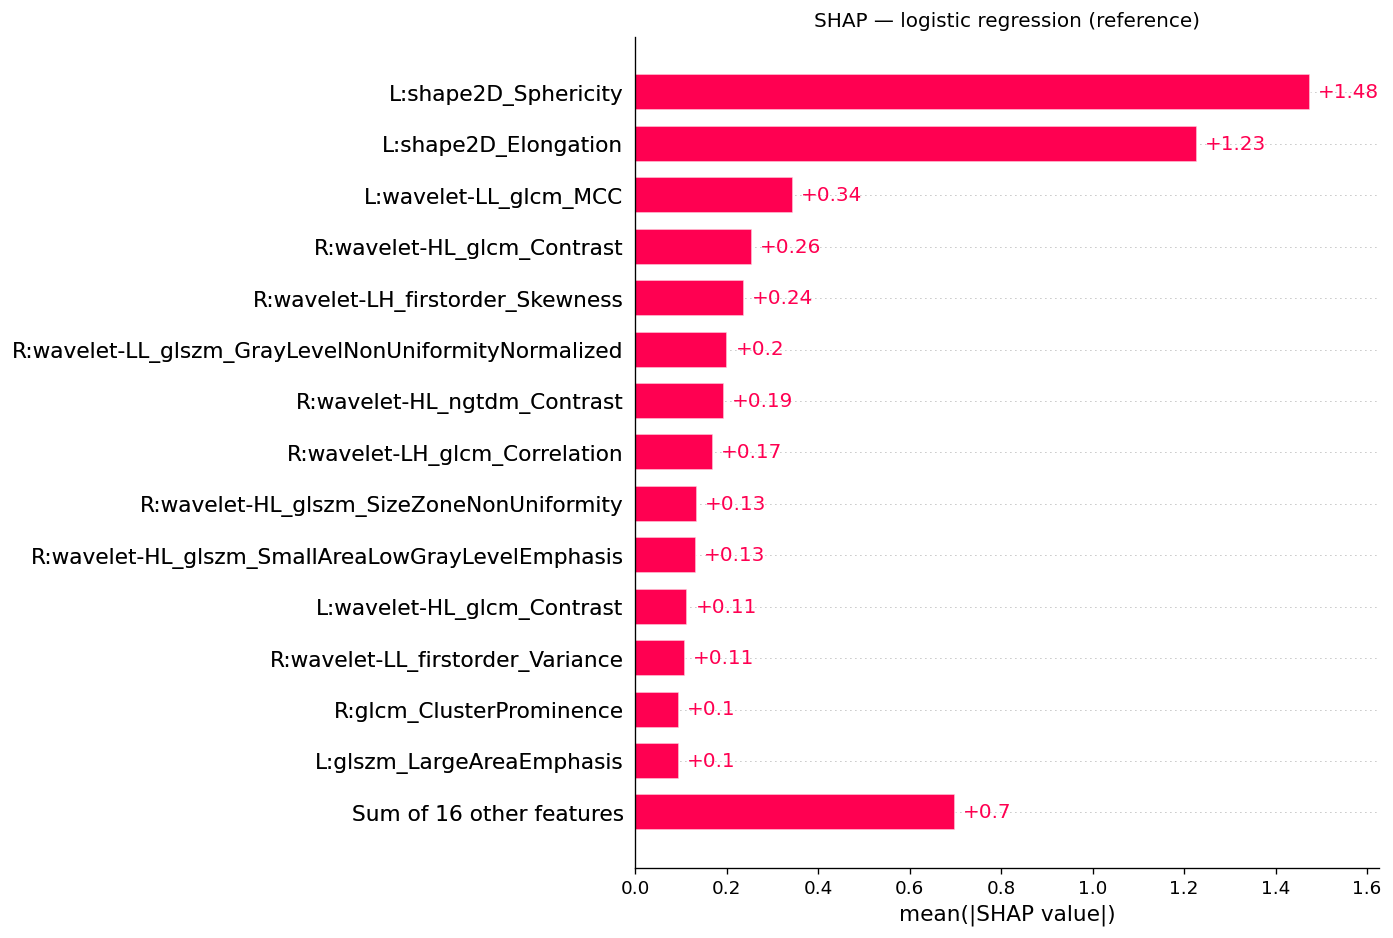

In [13]:
import shap
f = 0; tr, te = (master.fold != f).values, (master.fold == f).values
sc = StandardScaler().fit(X_all.values[tr]); idx = [stable.index(c) for c in selected[f]]
Xtr_s, Xte_s = sc.transform(X_all.values[tr])[:, idx], sc.transform(X_all.values[te])[:, idx]
short = [c.replace('lesion__', 'L:').replace('ring__', 'R:').replace('original_', '') for c in selected[f]]
N_SHAP = 120
rng = np.random.default_rng(SEED)
bg = Xtr_s[rng.choice(len(Xtr_s), 50, replace=False)]
xs = Xte_s[rng.choice(len(Xte_s), min(N_SHAP, len(Xte_s)), replace=False)]

model_A = MODELS[EXPERT_A]().fit(Xtr_s, y_all[tr])
explainer = shap.PermutationExplainer(lambda X: model_A.predict_proba(X)[:, 1], shap.maskers.Independent(bg), feature_names=short)
sv = explainer(xs, max_evals=2 * len(short) + 1)
plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title(f'SHAP — Expert A ({EXPERT_A}), fold {f}'); plt.savefig(f'{FIG_DIR}/shap_beeswarm_expertA.png', bbox_inches='tight'); plt.show()
plt.figure(); shap.plots.bar(sv, max_display=15, show=False)
plt.savefig(f'{FIG_DIR}/shap_bar_expertA.png', bbox_inches='tight'); plt.show()

lr = MODELS['LogReg']().fit(Xtr_s, y_all[tr])
sv_lr = shap.LinearExplainer(lr, bg, feature_names=short)(xs)
plt.figure(); shap.plots.bar(sv_lr, max_display=15, show=False)
plt.title('SHAP — logistic regression (reference)'); plt.savefig(f'{FIG_DIR}/shap_bar_logreg.png', bbox_inches='tight'); plt.show()
pd.DataFrame({'feature': selected[f], 'mean_abs_shap': np.abs(sv.values).mean(0)}) \
  .sort_values('mean_abs_shap', ascending=False).to_csv(f'{RES_DIR}/expertA_shap_importance.csv', index=False)

## 12. Explainability — LIME (Expert A): four representative cases
One true positive, true negative, false positive and false negative from the fold-0 test set.

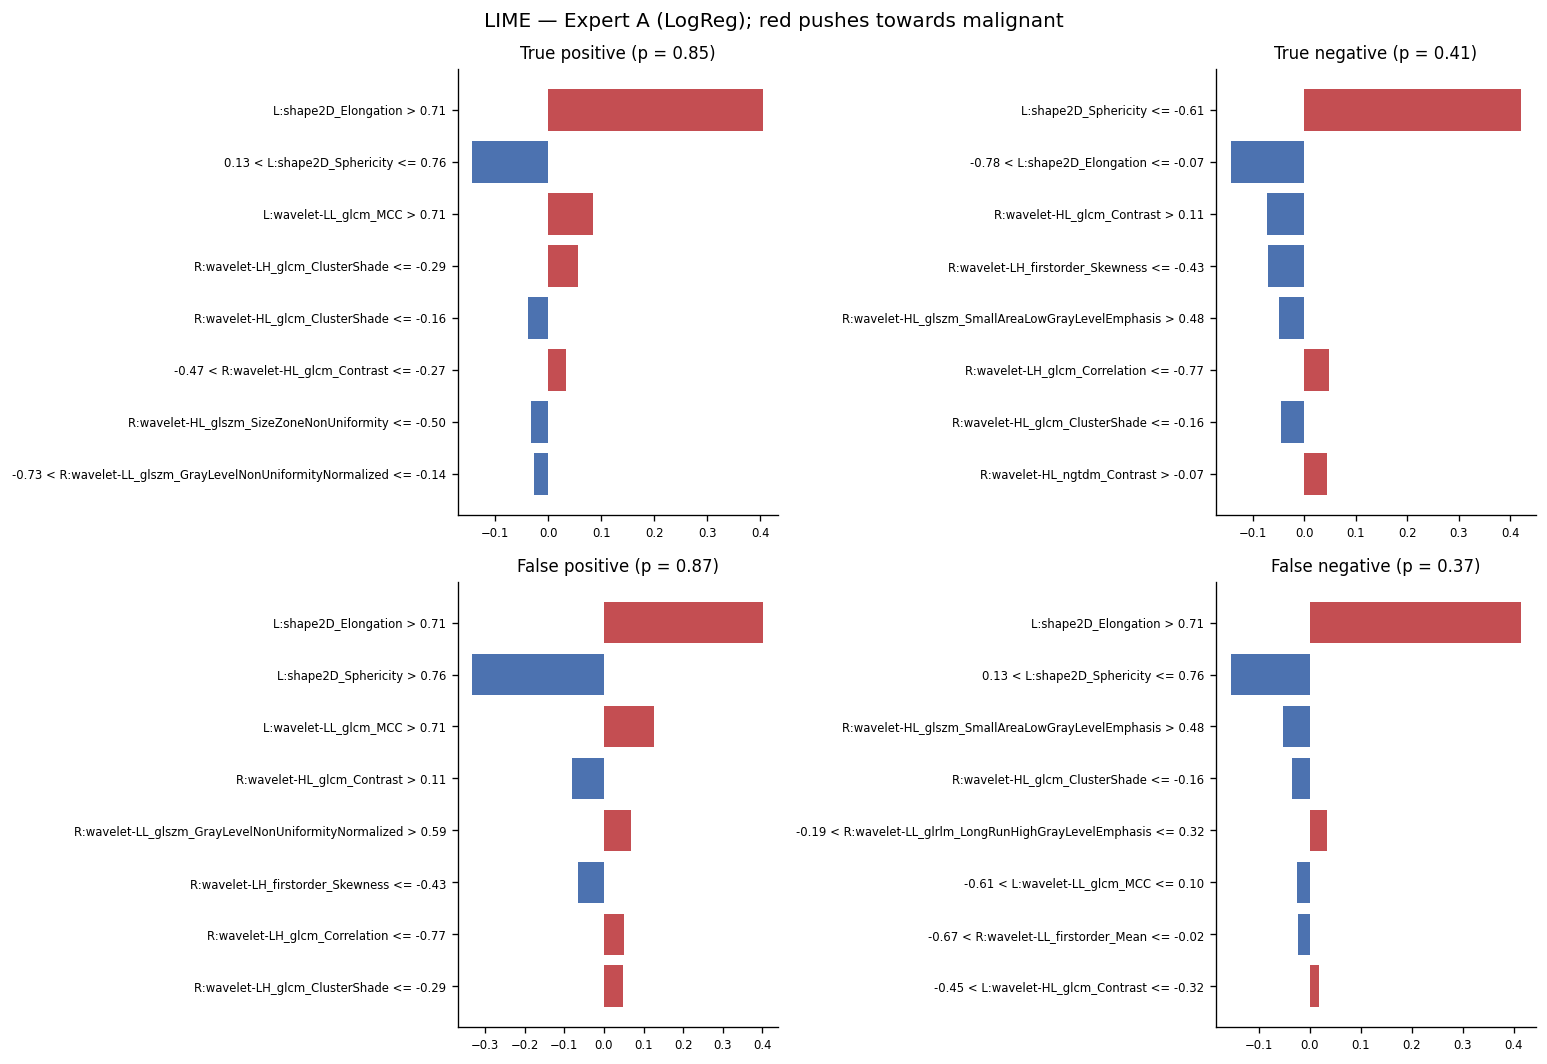

In [14]:
from lime.lime_tabular import LimeTabularExplainer
o = oofs[EXPERT_A][te].reset_index(drop=True)
pred = (o.prob >= o.thr).astype(int)
cases = {'True positive': (o.label == 1) & (pred == 1), 'True negative': (o.label == 0) & (pred == 0),
         'False positive': (o.label == 0) & (pred == 1), 'False negative': (o.label == 1) & (pred == 0)}
lime_exp = LimeTabularExplainer(Xtr_s, feature_names=short, class_names=['benign', 'malignant'],
                                discretize_continuous=True, random_state=SEED)
fig, axes = plt.subplots(2, 2, figsize=(13, 9)); axes = axes.ravel()
for ax, (title, mask) in zip(axes, cases.items()):
    if not mask.any(): ax.set_title(f'{title}: none'); ax.axis('off'); continue
    i = int(np.where(mask)[0][0])
    e = lime_exp.explain_instance(Xte_s[i], lambda X: model_A.predict_proba(X), num_features=8)
    w = e.as_list()[::-1]
    ax.barh([a for a, _ in w], [b for _, b in w], color=['#C44E52' if b > 0 else '#4C72B0' for _, b in w])
    ax.set_title(f'{title} (p = {o.prob[i]:.2f})', fontsize=10); ax.tick_params(labelsize=7)
fig.suptitle(f'LIME — Expert A ({EXPERT_A}); red pushes towards malignant'); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/lime_expertA_cases.png', bbox_inches='tight'); plt.show()

## 13. Outputs of Part 1 (all on Drive under `rsusfm_project/`)
| File | Used by |
|---|---|
| `master.csv` | all parts (folds + BI-RADS + scanner) |
| `common.py` | all parts |
| `radiomics/rad_orig_part*.csv`, `radiomics/icc.csv` | Part 3 (consistency score), reporting |
| `radiomics/concepts_fold{f}.csv` | **Part 3: teacher targets for RS-USFM** |
| `results/oof_expertA.csv` | **Part 4: Bayesian fusion** (prob, logit mean, logit SD = uncertainty) |
| `results/metrics_*.json`, `part1_metrics_full.csv` | Part 4 comparison tables |
| `figures/part1/*.png` | paper figures (300 dpi) |